In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/byukusengeezira/country-school/Country Schools.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Find uploaded CSV files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/byukusengeezira/country-school/Country Schools.csv


In [3]:

# Replace this path with the one shown above
df = pd.read_csv(
    "/kaggle/input/datasets/byukusengeezira/country-school/Country Schools.csv"
)

# Display first five rows
df.head()


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [4]:

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())



Dataset shape: (50, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB

Missing values:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64


In [5]:

# Display all rows containing missing values
df[df.isnull().any(axis=1)]



,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


In [6]:

# Remove rows where SNO is missing
df_clean = df.dropna(subset=["SNO"]).copy()

# Check the new dataset shape
print("Dataset shape:", df_clean.shape)


Dataset shape: (48, 8)


In [7]:

# Search for the TOTAL row
df_clean[
    df_clean["SNO"].str.strip().str.upper() == "TOTAL"
]



,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48


In [8]:

# Remove the TOTAL summary row
df_clean = df_clean[
    df_clean["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# Reset the index
df_clean.reset_index(drop=True, inplace=True)

# Check the shape
print("Dataset shape:", df_clean.shape)


Dataset shape: (47, 8)


In [9]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows with missing county names
df_clean = df_clean.dropna(subset=["SNO"])

# Remove the TOTAL summary row
df_clean = df_clean[
    df_clean["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# Reset the index
df_clean.reset_index(drop=True, inplace=True)

# Display the cleaned dataset shape
print("Cleaned dataset shape:", df_clean.shape)

# Display the first five rows
display(df_clean.head())


Cleaned dataset shape: (47, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [10]:

import pandas as pd
import os

# Find the uploaded Country Schools dataset
csv_files = []

for folder, subfolders, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(folder, file))

print("Available CSV files:")
for path in csv_files:
    print(path)


Available CSV files:
/kaggle/input/datasets/byukusengeezira/country-school/Country Schools.csv


In [11]:

# Load the CSV file
df = pd.read_csv(csv_files[0])

# Check whether it loaded successfully
print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [12]:

# Create a copy
df_clean = df.copy()

# Remove missing county names
df_clean.dropna(subset=["SNO"], inplace=True)

# Remove TOTAL summary row
df_clean = df_clean[
    df_clean["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Cleaned dataset shape:", df_clean.shape)


Cleaned dataset shape: (47, 8)


In [13]:

# Convert percentage values into numbers
df_clean["PercentageInstalled"] = (
    df_clean["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Display the first five rows
display(df_clean.head())


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [14]:

# Display statistical summary
display(df_clean.describe())


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
count,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000
mean,462.319149,311.255319,151.063830,63.919149,15396.127660,622.510638,24.000000
std,254.204395,228.997671,113.801009,25.847635,11479.580532,457.995342,13.711309
min,93.000000,8.000000,4.000000,4.550000,606.000000,16.000000,1.000000
25%,251.500000,156.500000,52.500000,50.305000,6166.000000,313.000000,12.500000
50%,413.000000,307.000000,130.000000,65.000000,13507.000000,614.000000,24.000000
75%,633.500000,408.500000,243.000000,84.935000,22838.500000,817.000000,35.500000
max,1238.000000,1200.000000,448.000000,96.930000,44338.000000,2400.000000,47.000000


In [15]:

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())


Missing values after cleaning:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Duplicate rows:
0


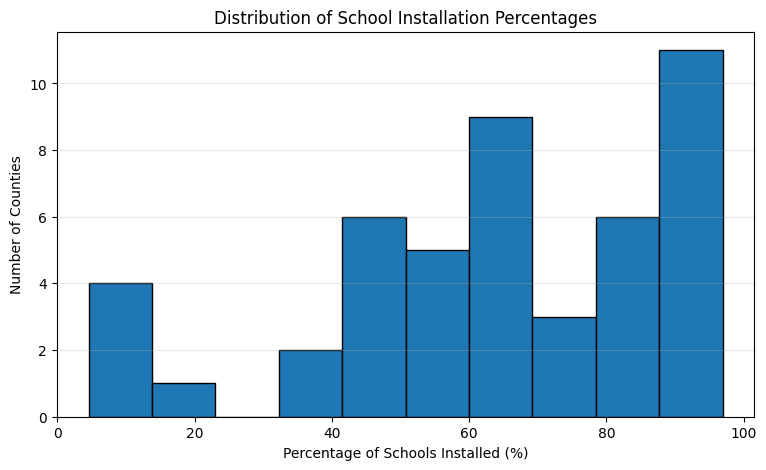

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["PercentageInstalled"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of School Installation Percentages")
plt.xlabel("Percentage of Schools Installed (%)")
plt.ylabel("Number of Counties")
plt.grid(axis="y", alpha=0.3)

plt.show()


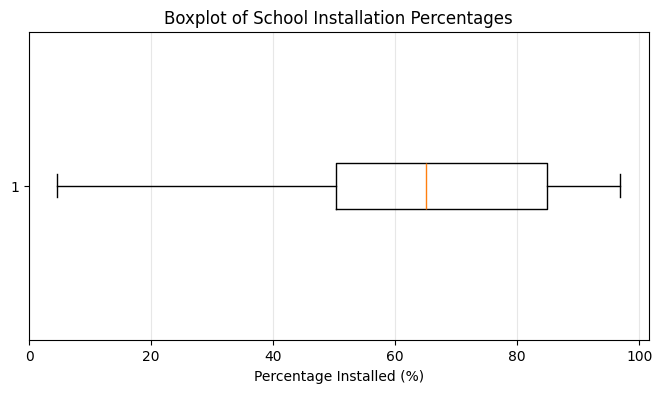

In [17]:

plt.figure(figsize=(8, 4))

plt.boxplot(
    df_clean["PercentageInstalled"],
    vert=False
)

plt.title("Boxplot of School Installation Percentages")
plt.xlabel("Percentage Installed (%)")
plt.grid(axis="x", alpha=0.3)

plt.show()


In [18]:

# Five counties with the lowest installation rates
print("Lowest installation percentages:")
display(
    df_clean.nsmallest(
        5, "PercentageInstalled"
    )[["SNO", "PercentageInstalled"]]
)

# Five counties with the highest installation rates
print("Highest installation percentages:")
display(
    df_clean.nlargest(
        5, "PercentageInstalled"
    )[["SNO", "PercentageInstalled"]]
)


Lowest installation percentages:


,SNO,PercentageInstalled
30,MANDERA,4.55
36,WAJIR,5.21
38,MARSABIT,5.80
0,TURKANA,10.34
28,GARISSA,19.02


Highest installation percentages:


,SNO,PercentageInstalled
3,KITUI,96.93
22,ElGEYO,95.93
14,LAMU,95.70
11,NANDI,94.92
24,KWALE,93.96


In [19]:

# Select numerical features
features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Create a copy for anomaly detection
df_anomaly = df_clean.copy()

# Track whether a county is an outlier
df_anomaly["IQR_Anomaly"] = False

for column in features:
    Q1 = df_anomaly[column].quantile(0.25)
    Q3 = df_anomaly[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Detect outliers
    outlier = (
        (df_anomaly[column] < lower_bound) |
        (df_anomaly[column] > upper_bound)
    )

    df_anomaly["IQR_Anomaly"] |= outlier

    print(f"\nColumn: {column}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {outlier.sum()}")

# Display counties flagged in any feature
print("\nCounties with potential anomalies:")

display(
    df_anomaly[df_anomaly["IQR_Anomaly"]]
    [["SNO"] + features]
)



Column: TOTALSCHOOLS
Lower bound: -321.50
Upper bound: 1206.50
Number of outliers: 1

Column: TotalSchoolsInstalled
Lower bound: -221.50
Upper bound: 786.50
Number of outliers: 2

Column: SchoolsPending
Lower bound: -233.25
Upper bound: 528.75
Number of outliers: 0

Column: PercentageInstalled
Lower bound: -1.64
Upper bound: 136.88
Number of outliers: 0

Column: InstalledLDDs
Lower bound: -18842.75
Upper bound: 47847.25
Number of outliers: 0

Column: InstalledTDDs
Lower bound: -443.00
Upper bound: 1573.00
Number of outliers: 2

Counties with potential anomalies:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0
13,MAKUENI,887.0,833.0,54.0,93.91,30973.0,1666.0


In [20]:

from sklearn.preprocessing import StandardScaler

features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Select numerical features
X = df_clean[features]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed")
print("Shape:", X_scaled.shape)


Standardization completed
Shape: (47, 6)


In [21]:

import pandas as pd
import numpy as np
import os

# STEP 1: Find the Country Schools CSV file
csv_path = None

for folder, _, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "country schools.csv":
            csv_path = os.path.join(folder, file)
            break
    if csv_path is not None:
        break

if csv_path is None:
    raise FileNotFoundError(
        "Country Schools.csv was not found in Kaggle Input"
    )

# STEP 2: Load original dataset
df = pd.read_csv(csv_path)

# STEP 3: Create cleaned dataset
df_clean = df.copy()

# Remove missing county names
df_clean = df_clean.dropna(subset=["SNO"])

# Remove TOTAL row
df_clean = df_clean[
    df_clean["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# STEP 4: Convert percentages to numeric
df_clean["PercentageInstalled"] = (
    df_clean["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .astype(float)
)

# STEP 5: Reset index
df_clean.reset_index(drop=True, inplace=True)

# STEP 6: Verify
print("Dataset loaded successfully!")
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())


Dataset loaded successfully!
Cleaned dataset shape: (47, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [22]:

from sklearn.preprocessing import StandardScaler

features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = df_clean[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Shape:", X_scaled.shape)



Standardization completed!
Shape: (47, 6)


In [23]:

from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

predictions = model.fit_predict(X_scaled)

df_anomaly = df_clean.copy()
df_anomaly["IsolationForest"] = predictions

print("Detected anomalies:")

display(
    df_anomaly[
        df_anomaly["IsolationForest"] == -1
    ][["SNO"] + features]
)

print(
    "Total anomalies:",
    (predictions == -1).sum()
)


Detected anomalies:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0
17,KAKAMEGA,880.0,572.0,308.0,65.00,44338.0,1144.0


Total anomalies: 3


### Isolation Forest Results and Interpretation

Isolation Forest was applied to 47 counties using six numerical features. The algorithm identified three anomalous counties: Turkana, Kitui, and Kakamega.

**Turkana:** Has a low installation percentage of 10.34%, with 321 schools still pending.

**Kitui:** Has 1,200 installed schools out of 1,238, representing 96.93% installation coverage.

**Kakamega:** Has 44,338 installed LDDs, the highest number in the dataset.

**Conclusion:** The results indicate that some counties have unusual installation characteristics. These anomalies do not necessarily represent errors but may require further investigation.

In [24]:

# Compare the two anomaly detection methods
comparison = df_anomaly[["SNO", "IsolationForest"]].copy()

comparison["IQR_Anomaly"] = False

for column in features:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    comparison["IQR_Anomaly"] |= (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    )

comparison["IF_Anomaly"] = (
    comparison["IsolationForest"] == -1
)

display(
    comparison[
        comparison["IQR_Anomaly"] |
        comparison["IF_Anomaly"]
    ]
)


,SNO,IsolationForest,IQR_Anomaly,IF_Anomaly
0,TURKANA,-1,False,True
3,KITUI,-1,True,True
13,MAKUENI,1,True,False
17,KAKAMEGA,-1,False,True


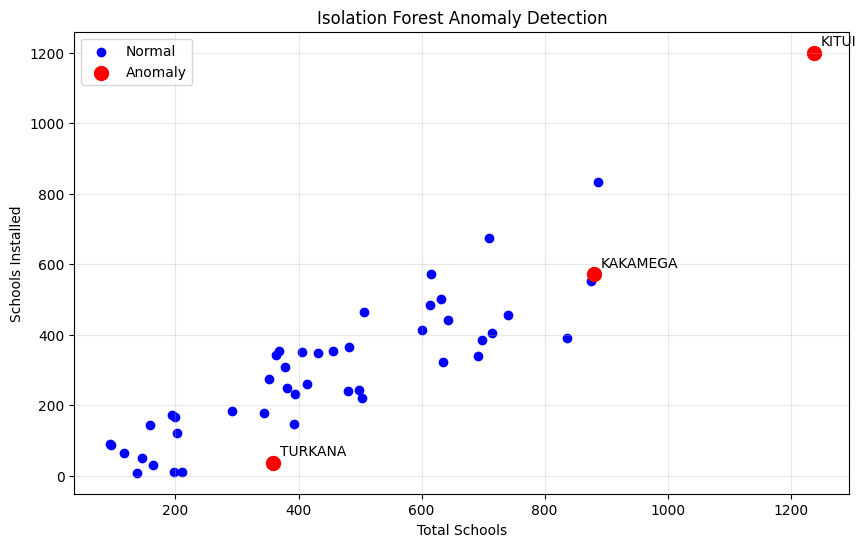

In [25]:

import matplotlib.pyplot as plt

normal = df_anomaly[df_anomaly["IsolationForest"] == 1]
anomalies = df_anomaly[df_anomaly["IsolationForest"] == -1]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["TOTALSCHOOLS"],
    normal["TotalSchoolsInstalled"],
    color="blue",
    label="Normal"
)

plt.scatter(
    anomalies["TOTALSCHOOLS"],
    anomalies["TotalSchoolsInstalled"],
    color="red",
    label="Anomaly",
    s=100
)

for _, row in anomalies.iterrows():
    plt.annotate(
        row["SNO"],
        (row["TOTALSCHOOLS"], row["TotalSchoolsInstalled"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Total Schools")
plt.ylabel("Schools Installed")
plt.title("Isolation Forest Anomaly Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Comparison of IQR and Isolation Forest

The IQR method detected two anomalous counties: Kitui and Makueni. Isolation Forest detected three: Turkana, Kitui, and Kakamega.

Kitui was identified by both methods because it has exceptionally high school installation figures. Turkana and Kakamega were detected only by Isolation Forest, indicating unusual combinations of numerical characteristics.

The results demonstrate that different anomaly detection techniques can identify different observations. IQR detects extreme values in individual features, while Isolation Forest evaluates unusual patterns across multiple features.

The identified anomalies should be investigated further before drawing conclusions about data quality or installation performance.

In [26]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Select numerical features
features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Select data
X = df_clean[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared successfully!")
print("Shape:", X_scaled.shape)


Data prepared successfully!
Shape: (47, 6)


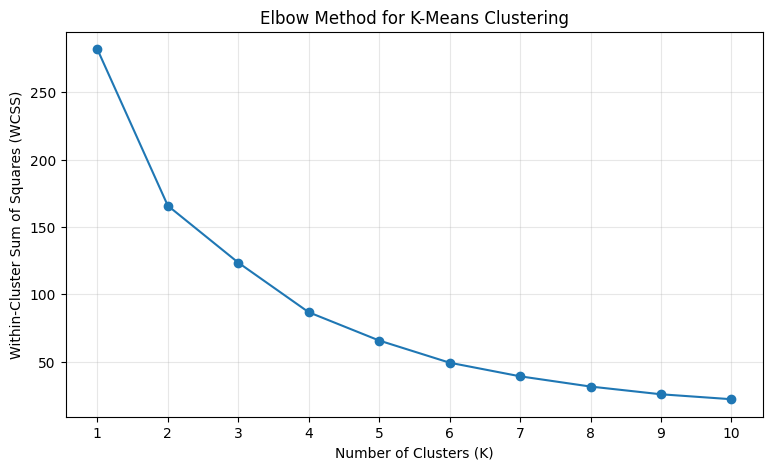

In [27]:

# Test different numbers of clusters
wcss = []

K_values = range(1, 11)

for k in K_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(list(K_values))
plt.grid(alpha=0.3)

plt.show()


###  Interpretation of the Elbow Method

The Elbow Method was used to determine the appropriate number of clusters for K-Means clustering using the Country Schools dataset containing 47 counties and six numerical features.

**Observations:**

The graph shows that the Within-Cluster Sum of Squares (WCSS) decreases as the number of clusters (K) increases from 1 to 10.

- At K=1, the WCSS is approximately 282, indicating that all counties are grouped into one cluster with high variation.
- At K=2, the WCSS decreases significantly to approximately 166.
- At K=3, the WCSS decreases to approximately 123.
- At K=4, the WCSS decreases further to approximately 87.
- Beyond K=4, the WCSS continues to decrease, but the improvements become gradually smaller.

**Interpretation:**

The sharp decrease in WCSS at lower K values indicates that dividing counties into groups improves their similarity within clusters.

The graph suggests that K=4 may be a reasonable choice because the curve begins to flatten around this point. However, there is no clearly defined elbow.

**Conclusion:**

K=4 is considered a candidate for the number of clusters. The Silhouette Score will be calculated to verify whether this is an appropriate choice before performing the final K-Means clustering.

K=2, Silhouette Score=0.3599
K=3, Silhouette Score=0.3023
K=4, Silhouette Score=0.3594
K=5, Silhouette Score=0.3453
K=6, Silhouette Score=0.3908
K=7, Silhouette Score=0.3875
K=8, Silhouette Score=0.4251
K=9, Silhouette Score=0.4171
K=10, Silhouette Score=0.4167


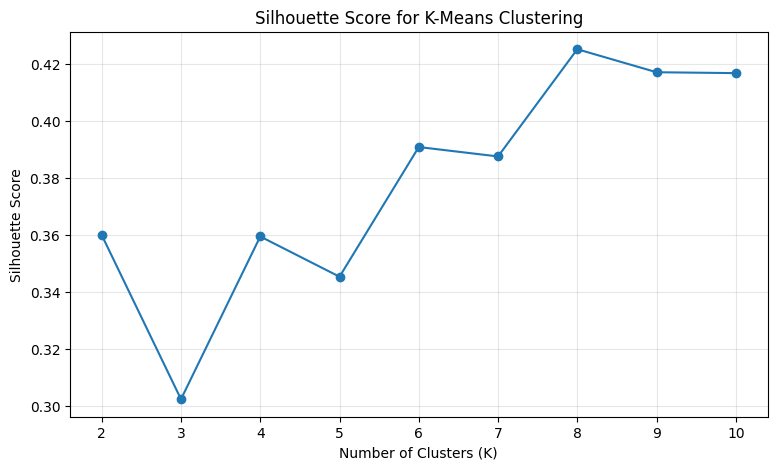


Best K based on Silhouette Score: 8


In [28]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []

K_values = range(2, 11)

for k in K_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

# Plot the Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_values))
plt.grid(alpha=0.3)

plt.show()

# Find the best K based on silhouette score
best_k = list(K_values)[
    silhouette_scores.index(max(silhouette_scores))
]

print("\nBest K based on Silhouette Score:", best_k)


###  Silhouette Score Interpretation

The Silhouette Score was calculated for K-Means clustering using values of K ranging from 2 to 10.

The results show that the highest Silhouette Score is approximately 0.425 at K=8. This indicates that eight clusters provide the best separation among the tested clustering solutions according to this evaluation metric.

At K=4, the Silhouette Score is approximately 0.360, which is lower than the score obtained at K=8.

Although K=8 achieves the highest score, the number of counties in each cluster and the practical meaning of the clusters should also be examined.

**Conclusion:** K=8 was selected for the initial K-Means clustering experiment based on the highest Silhouette Score. The resulting clusters will be evaluated to determine whether they provide meaningful groupings of counties.

In [29]:

from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

# Fit model and assign clusters
cluster_labels = kmeans.fit_predict(X_scaled)

# Create a new dataframe
df_cluster = df_clean.copy()

# Add cluster labels
df_cluster["Cluster"] = cluster_labels

# Display county assignments
display(
    df_cluster[
        ["SNO", "PercentageInstalled", "Cluster"]
    ].sort_values("Cluster")
)

# Count counties in each cluster
print("\nNumber of counties in each cluster:")
print(df_cluster["Cluster"].value_counts().sort_index())


,SNO,PercentageInstalled,Cluster
2,WEST POKOT,48.59,0
29,LAIKIPIA,62.33,0
26,KERICHO,43.54,0
44,KAJIADO,58.73,0
42,THARAKA NITHI,62.71,0
37,NYANDARUA,51.45,0
35,NYERI,37.50,0
33,KIAMBU,49.90,0
45,EMBU,65.09,0
21,BUSIA,80.32,1



Number of counties in each cluster:
Cluster
0    9
1    8
2    2
3    2
4    6
5    6
6    7
7    7
Name: count, dtype: int64


In [30]:

# Calculate average values for each cluster
cluster_summary = df_cluster.groupby("Cluster")[
    [
        "TOTALSCHOOLS",
        "TotalSchoolsInstalled",
        "SchoolsPending",
        "PercentageInstalled",
        "InstalledLDDs",
        "InstalledTDDs"
    ]
].mean().round(2)

# Add number of counties per cluster
cluster_summary.insert(
    0,
    "CountyCount",
    df_cluster.groupby("Cluster").size()
)

display(cluster_summary)


,CountyCount,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,,,,
0,9,411.00,216.22,194.78,53.32,8248.33,432.44
1,8,404.88,336.50,68.38,83.58,18445.38,673.00
2,2,810.50,514.00,296.50,63.27,41541.00,1028.00
3,2,1062.50,1016.50,46.00,95.42,36567.50,2033.00
4,6,741.67,398.50,343.17,53.51,17257.50,797.00
5,6,202.33,24.17,178.17,13.08,1785.17,48.33
6,7,151.43,120.43,31.00,80.49,6010.71,240.86
7,7,617.29,507.29,110.00,82.19,27038.86,1014.57


### K-Means Clustering Results and Interpretation

K-Means clustering was performed on the Country Schools dataset containing 47 counties and six standardized numerical features. Eight clusters were selected based on the highest Silhouette Score among the tested values.

The results show that counties have different school installation characteristics.

**Cluster 0:** Contains 9 counties with an average installation percentage of 53.32%. These counties have moderate installation coverage.

**Cluster 1:** Contains 8 counties with an average installation percentage of 83.58%, indicating relatively high installation coverage.

**Cluster 2:** Contains Kakamega and Bungoma. These counties have large numbers of schools and the highest average installed LDD count of 41,541.

**Cluster 3:** Contains Kitui and Makueni, with the highest average installation percentage of 95.42%. These counties also have high numbers of installed schools.

**Cluster 4:** Contains 6 counties with an average installation percentage of 53.51% and approximately 343 pending schools per county.

**Cluster 5:** Contains Mandera, Marsabit, Wajir, Garissa, Turkana, and Samburu. These counties have the lowest average installation percentage of 13.08%.

**Cluster 6:** Contains 7 counties with an average installation percentage of 80.49%. These counties generally have smaller school counts than the high-coverage counties in Cluster 7.

**Cluster 7:** Contains 7 counties with an average installation percentage of 82.19% and approximately 507 installed schools per county.

**Conclusion:** K-Means clustering successfully grouped counties according to similarities in their school installation characteristics. Cluster 5 has the lowest installation coverage and may require priority attention, while Cluster 3 has the highest installation coverage. The results can support planning and resource allocation for school installation activities.

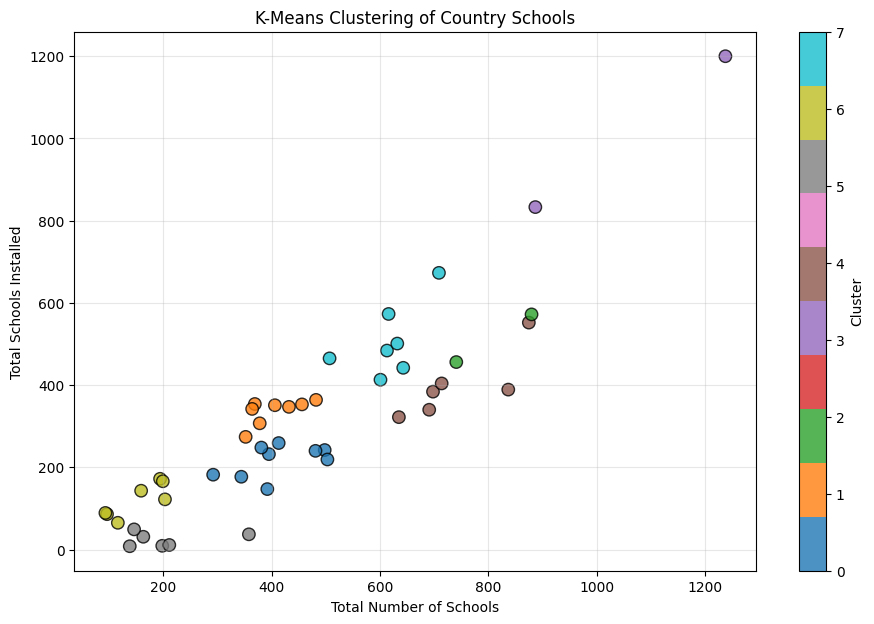

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    df_cluster["TOTALSCHOOLS"],
    df_cluster["TotalSchoolsInstalled"],
    c=df_cluster["Cluster"],
    cmap="tab10",
    s=80,
    alpha=0.8,
    edgecolors="black"
)

plt.title("K-Means Clustering of Country Schools")
plt.xlabel("Total Number of Schools")
plt.ylabel("Total Schools Installed")

plt.colorbar(scatter, label="Cluster")

plt.grid(alpha=0.3)
plt.show()


### Interpretation of the K-Means Scatter Plot

The scatter plot illustrates the distribution of 47 counties into eight clusters using K-Means clustering.

The X-axis represents the total number of schools, while the Y-axis represents the number of installed schools. Each point represents one county, and different colors indicate different clusters.

The graph shows that counties differ in their school installation characteristics. Some clusters contain counties with high numbers of installed schools, while others contain counties with fewer installations.

Cluster 3 includes Kitui and Makueni, which have particularly high numbers of installed schools.

The clustering algorithm used six standardized numerical features, although only two are displayed in the scatter plot.

The results demonstrate that K-Means can group counties according to similarities in their school installation characteristics.

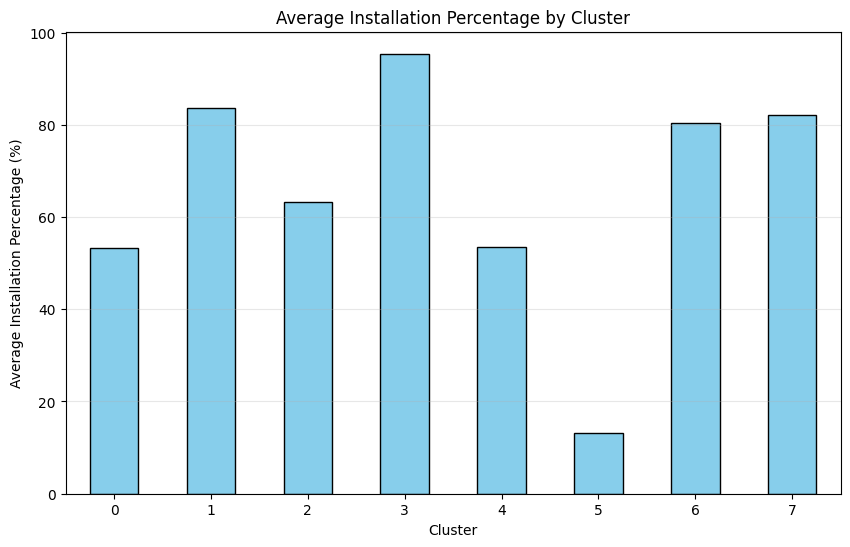

In [32]:

# Calculate average installation percentage
cluster_avg = df_cluster.groupby(
    "Cluster"
)["PercentageInstalled"].mean()

plt.figure(figsize=(10, 6))

cluster_avg.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Average Installation Percentage by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Installation Percentage (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()


### Interpretation of Average Installation Percentage by Cluster

The bar chart compares the average school installation percentage across the eight clusters.

Cluster 3 has the highest average installation percentage of 95.42%, followed by Cluster 1 at 83.58%, Cluster 7 at 82.19%, and Cluster 6 at 80.49%.

Cluster 5 has the lowest average installation percentage of 13.08%. This cluster includes Mandera, Marsabit, Wajir, Garissa, Turkana, and Samburu.

Clusters 0 and 4 have moderate installation percentages of 53.32% and 53.51%, respectively.

The results show that school installation progress differs significantly across the clusters. Counties in Cluster 5 may require greater attention to improve installation coverage, while counties in Cluster 3 demonstrate very high installation progress.

### K-Means Cluster Visualization Interpretation

The scatter plot displays the distribution of counties according to the total number of schools and the number of installed schools. Different colors represent the eight clusters identified by K-Means.

The graph shows that counties differ considerably in school counts and installation activity. Some groups contain counties with large numbers of installed schools, while others contain counties with fewer installations.

The bar chart compares the average installation percentage across the eight clusters.

Cluster 3 has the highest average installation percentage of 95.42%, followed by Cluster 1 at 83.58% and Cluster 7 at 82.19%.

Cluster 5 has the lowest average installation percentage of 13.08%, indicating substantially lower installation coverage than the other groups.

These findings demonstrate that clustering can identify groups of counties with similar installation characteristics and help highlight differences in installation progress.

## Conclusion

This lab focused on data preprocessing, anomaly detection, and cluster analysis using the Country Schools dataset.

The original dataset contained 50 records and 8 columns. After removing two empty records and the TOTAL summary row, 47 county records remained for analysis. The installation percentage column was converted into numerical values to support statistical analysis and machine learning.

For anomaly detection, two methods were applied: the Interquartile Range (IQR) method and Isolation Forest. The IQR method identified two anomalous counties, Kitui and Makueni, while Isolation Forest identified three: Turkana, Kitui, and Kakamega. Kitui was detected by both methods.

For cluster analysis, K-Means clustering was applied using six standardized numerical features. The Elbow Method and Silhouette Score were used to evaluate the number of clusters. Eight clusters were selected based on the highest Silhouette Score among the tested values.

The clustering results showed differences in school installation characteristics across counties. Cluster 3 had the highest average installation percentage of 95.42%, while Cluster 5 had the lowest at 13.08%.

In conclusion, anomaly detection helped identify counties with unusual installation characteristics, while cluster analysis grouped counties according to similarities in school installation patterns. These techniques can support data-driven planning and help identify counties requiring further attention.